<a href="https://colab.research.google.com/github/messagmo/leo-predictive-handover/blob/main/notebooks/00_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1-Environnement et dépôt GitHub

installation de l'environnement

In [ ]:
!pip install -q -U sgp4 skyfield numpy pandas scipy matplotlib plotly torch gymnasium tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


vérification de l’installation

In [ ]:
import numpy, pandas, scipy, matplotlib, torch, gymnasium, sgp4, skyfield
print("sgp4", sgp4.__version__, "| skyfield", skyfield.__version__, "| torch", torch.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


sgp4 2.27 | skyfield 1.55 | torch 2.15.0+cu132


Premier test de calcul orbital

In [ ]:
import urllib.request

url = "https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=tle"
urllib.request.urlretrieve(url, "starlink.tle")

lines = open("starlink.tle").read().strip().splitlines()
print("Nombre de satellites :", len(lines) // 3)
print(lines[0]); print(lines[1]); print(lines[2])

Nombre de satellites : 10611
STARLINK-1008           
1 44714U 19074B   26317.27120044  .00204210  00000+0  16278-2 0  9994
2 44714  53.1439  62.8129 0001827 337.0505  23.0431 15.70026012387506


2-Données orbitales (orbit.py)

préparer les dossiers

In [2]:
!mkdir -p src data

import urllib.request
url = "https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=tle"
urllib.request.urlretrieve(url, "data/starlink.tle")

lines = open("data/starlink.tle").read().strip().splitlines()
print("Nombre de satellites :", len(lines) // 3)

Nombre de satellites : 10611


créer src/orbit.py

In [3]:
%%writefile src/orbit.py
"""orbit.py : TLE, propagation SGP4 et visibilité depuis un utilisateur (fixe ou mobile)."""
import math, os, urllib.request
import numpy as np
from sgp4.api import Satrec, SatrecArray, jday

CELESTRAK_URL = "https://celestrak.org/NORAD/elements/gp.php?GROUP={group}&FORMAT=tle"
A_WGS84_KM = 6378.137
E2 = (1 / 298.257223563) * (2 - 1 / 298.257223563)   # excentricité² WGS84


def download_tle(path="data/starlink.tle", group="starlink"):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    urllib.request.urlretrieve(CELESTRAK_URL.format(group=group), path)
    return path


def load_tle(path):
    """Lit un fichier TLE (3 lignes par satellite) -> liste de (nom, Satrec)."""
    lines = [l.rstrip() for l in open(path) if l.strip()]
    return [(lines[i].strip(), Satrec.twoline2rv(lines[i + 1], lines[i + 2]))
            for i in range(0, len(lines) - 2, 3)]


def filter_tle(sats, ref_jd, mm_min=14.9, mm_max=15.2, bstar_max=1e-4, max_age_days=30):
    """Filtre du HHS : mouvement moyen (tours/jour), |B*| et âge du TLE."""
    kept = []
    for name, s in sats:
        mm = s.no_kozai * 1440.0 / (2 * math.pi)             # rad/min -> tours/jour
        age = ref_jd - (s.jdsatepoch + s.jdsatepochF)
        if mm_min <= mm <= mm_max and abs(s.bstar) <= bstar_max and abs(age) <= max_age_days:
            kept.append((name, s))
    return kept


def time_grid(start, duration_s, step_s):
    """Grille de temps (jd, fr) à partir d'un datetime UTC."""
    jd0, fr0 = jday(start.year, start.month, start.day, start.hour, start.minute,
                    start.second + start.microsecond / 1e6)
    t = fr0 + np.arange(0, duration_s + 1e-9, step_s) / 86400.0
    return jd0 + np.floor(t), t - np.floor(t)


def gmst_rad(jd, fr):
    """Angle sidéral de Greenwich (UT1 ≈ UTC)."""
    T = ((jd - 2451545.0) + fr) / 36525.0
    sec = 67310.54841 + (876600 * 3600 + 8640184.812866) * T + 0.093104 * T**2 - 6.2e-6 * T**3
    return np.deg2rad((sec % 86400.0) / 240.0)


def propagate_ecef(sats, jd, fr):
    """Positions ECEF (km) de tous les satellites : tableau (n_sat, n_temps, 3)."""
    err, r, _ = SatrecArray([s for _, s in sats]).sgp4(jd, fr)   # r en TEME
    r = np.array(r)
    r[err != 0] = np.nan                                          # satellites en erreur
    th = gmst_rad(jd, fr)
    c, s = np.cos(th), np.sin(th)
    x = r[..., 0] * c + r[..., 1] * s
    y = -r[..., 0] * s + r[..., 1] * c
    return np.stack([x, y, r[..., 2]], axis=-1)


def geodetic_to_ecef(lat_deg, lon_deg, alt_m=0.0):
    """Position ECEF (km) ; accepte des scalaires ou des tableaux (trajectoire)."""
    lat, lon = np.radians(lat_deg), np.radians(lon_deg)
    h = np.asarray(alt_m, dtype=float) / 1000.0
    N = A_WGS84_KM / np.sqrt(1 - E2 * np.sin(lat) ** 2)
    return np.stack([(N + h) * np.cos(lat) * np.cos(lon),
                     (N + h) * np.cos(lat) * np.sin(lon),
                     (N * (1 - E2) + h) * np.sin(lat)], axis=-1)


def up_vector(lat_deg, lon_deg):
    lat, lon = np.radians(lat_deg), np.radians(lon_deg)
    return np.stack([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)], axis=-1)


def look_angles(sat_ecef, obs_ecef, up):
    """Élévation (degrés) et distance oblique (km), tableaux (n_sat, n_temps)."""
    n_t = sat_ecef.shape[1]
    obs = np.broadcast_to(obs_ecef, (n_t, 3))
    up = np.broadcast_to(up, (n_t, 3))
    with np.errstate(invalid="ignore"):
        rho = sat_ecef - obs[None, :, :]
        rng = np.linalg.norm(rho, axis=-1)
        sin_el = np.einsum("stk,tk->st", rho, up) / rng
        el = np.degrees(np.arcsin(np.clip(sin_el, -1, 1)))
    return el, rng


def remaining_visibility(visible, step_s):
    """Temps de visibilité restant (s) à chaque instant (limité à la fin de la fenêtre)."""
    rem = np.zeros(visible.shape)
    for t in range(visible.shape[1] - 1, -1, -1):
        nxt = rem[:, t + 1] if t + 1 < visible.shape[1] else 0.0
        rem[:, t] = np.where(visible[:, t], nxt + step_s, 0.0)
    return rem


def compute_visibility(sats, start, duration_s, step_s, lat, lon, alt_m=0.0, el_min=5.0):
    """Pipeline complet. lat/lon/alt_m : scalaires (terminal fixe) ou tableaux de
    longueur n_temps (terminal mobile)."""
    jd, fr = time_grid(start, duration_s, step_s)
    sat_ecef = propagate_ecef(sats, jd, fr)
    el, rng = look_angles(sat_ecef, geodetic_to_ecef(lat, lon, alt_m), up_vector(lat, lon))
    visible = el >= el_min                                        # NaN -> False
    return {"names": [n for n, _ in sats], "jd": jd, "fr": fr, "step_s": step_s,
            "el": el, "range_km": rng, "visible": visible,
            "remaining_s": remaining_visibility(visible, step_s)}

Writing src/orbit.py


premier test

In [5]:
!pip install -q sgp4 skyfield gymnasium

In [6]:
import sgp4, skyfield
print("sgp4", sgp4.__version__, "| skyfield", skyfield.__version__)

sgp4 2.27 | skyfield 1.55


10611 satellites -> 10576 après filtre
Satellites visibles : min 209 | moyenne 226.4 | max 248
Changements de meilleur satellite en 1 h (sans hystérésis) : 126


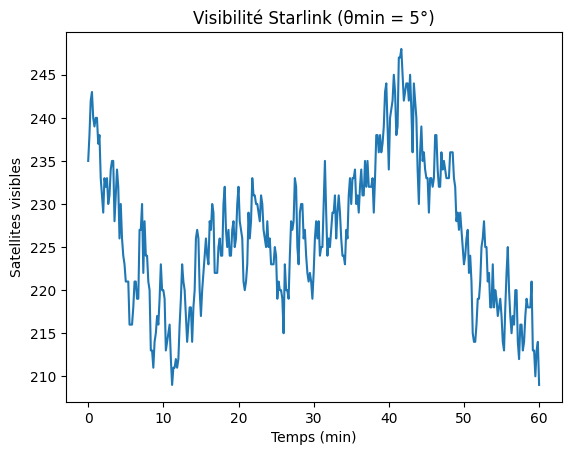

In [10]:
import sys, importlib
sys.path.insert(0, "src")
import orbit; importlib.reload(orbit)
from datetime import datetime, timezone
import numpy as np, matplotlib.pyplot as plt
from sgp4.api import jday

now = datetime.now(timezone.utc)
jd_now = sum(jday(now.year, now.month, now.day, now.hour, now.minute, now.second))

sats_all = orbit.load_tle("data/starlink.tle")
# CHANGÉ : plage élargie (14,9 à 16,0 tours/jour) et seuil B* large
sats = orbit.filter_tle(sats_all, jd_now, mm_min=14.9, mm_max=16.0, bstar_max=1e-1)
print(len(sats_all), "satellites ->", len(sats), "après filtre")

res = orbit.compute_visibility(sats, now, duration_s=3600, step_s=10,
                               lat=24.7136, lon=46.6753, alt_m=600, el_min=5.0)

nvis = res["visible"].sum(axis=0)
print("Satellites visibles : min", nvis.min(), "| moyenne", round(nvis.mean(), 1), "| max", nvis.max())

best = np.argmax(np.where(res["visible"], res["el"], -90), axis=0)
print("Changements de meilleur satellite en 1 h (sans hystérésis) :", int((best[1:] != best[:-1]).sum()))

plt.plot(np.arange(len(nvis)) * 10 / 60, nvis)
plt.xlabel("Temps (min)"); plt.ylabel("Satellites visibles"); plt.title("Visibilité Starlink (θmin = 5°)")
plt.show()

Voir l’effet de chaque critère:combien de satellites restent selon le seuil de B*.

In [8]:
import math
mm = np.array([s.no_kozai * 1440 / (2 * math.pi) for _, s in sats_all])
bs = np.array([abs(s.bstar) for _, s in sats_all])

print("Mouvement moyen 14,9-15,2 tours/jour :", int(((mm >= 14.9) & (mm <= 15.2)).sum()))
for b in [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]:
    n = int(((mm >= 14.9) & (mm <= 15.2) & (bs <= b)).sum())
    print(f"  + |B*| <= {b:g} :", n)

Mouvement moyen 14,9-15,2 tours/jour : 244
  + |B*| <= 0.0001 : 57
  + |B*| <= 0.0005 : 85
  + |B*| <= 0.001 : 99
  + |B*| <= 0.005 : 216
  + |B*| <= 0.01 : 244


Valider avec Skyfield

In [11]:
from datetime import timedelta
from skyfield.api import load, wgs84, EarthSatellite

ts = load.timescale()
k = 60                                   # instant n°60 -> t = 600 s
i = int(np.argmax(res["visible"][:, k]))
name, satrec = sats[i]
site = wgs84.latlon(24.7136, 46.6753, elevation_m=600)
t = ts.from_datetime(now + timedelta(seconds=k * 10))
alt, az, dist = (EarthSatellite.from_satrec(satrec, ts) - site).at(t).altaz()

print(name)
print("Notre élévation  :", round(float(res["el"][i, k]), 3), "°")
print("Skyfield         :", round(alt.degrees, 3), "°")
print("Écart            :", round(abs(float(res["el"][i, k]) - alt.degrees), 4), "°")

STARLINK-1012
Notre élévation  : 10.101 °
Skyfield         : 10.102 °
Écart            : 0.0006 °
